#import library

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error

#data import

In [2]:
from google.colab import files
uploaded=files.upload()

Saving cleaned_2.xlsx to cleaned_2.xlsx


In [4]:
df=pd.read_excel('cleaned_2.xlsx')

In [6]:
df

,Unnamed: 0,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,0.0,10.5,2011-04-18 19:55:00 UTC,-73.984565,40.745372,-73.951843,40.777743,5.0
1,1.0,12.0,2014-01-09 07:48:00 UTC,-73.991572,40.749877,-73.964142,40.757180,1.0
2,2.0,9.0,2014-09-14 01:14:00 UTC,-74.000412,40.718410,-73.999255,40.719967,2.0
3,3.0,9.3,2012-03-18 15:04:01 UTC,-73.991999,40.719834,-73.983515,40.743818,1.0
4,4.0,8.5,2012-02-06 13:09:00 UTC,-73.966765,40.761547,-73.990493,40.750787,1.0
...,...,...,...,...,...,...,...,...
205666,209707.0,16.5,2009-10-08 23:18:00 UTC,-73.972182,40.760631,-73.984864,40.703854,2.0
205667,209708.0,44.5,2011-07-11 06:14:00 UTC,-73.947578,40.779308,-73.898623,40.851420,1.0
205668,209710.0,27.7,2011-02-06 03:25:00 UTC,-73.993135,40.689995,-73.967445,40.799485,1.0
205669,209711.0,8.1,2011-12-15 12:47:00 UTC,-73.981945,40.770162,-73.991647,40.750747,1.0


In [8]:
df.head()
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205671 entries, 0 to 205670
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         205670 non-null  float64
 1   fare_amount        205670 non-null  float64
 2   pickup_datetime    205670 non-null  object 
 3   pickup_longitude   205670 non-null  float64
 4   pickup_latitude    205670 non-null  float64
 5   dropoff_longitude  205670 non-null  float64
 6   dropoff_latitude   205670 non-null  float64
 7   passenger_count    205670 non-null  float64
dtypes: float64(7), object(1)
memory usage: 12.6+ MB


#data cleaning

In [9]:
# Remove unnecessary column
df.drop(columns=['Unnamed: 0'], inplace=True, errors='ignore')

# Remove missing values
df.dropna(inplace=True)

# Convert datetime
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce'
)

df.dropna(inplace=True)

# Remove invalid fares and passenger counts
df = df[
    (df['fare_amount'] > 0) &
    (df['fare_amount'] <= 200) &
    (df['passenger_count'] >= 1) &
    (df['passenger_count'] <= 6)
]

# Remove geographically invalid coordinates
df = df[
    df['pickup_longitude'].between(-74.3, -73.5) &
    df['dropoff_longitude'].between(-74.3, -73.5) &
    df['pickup_latitude'].between(40.4, 41.0) &
    df['dropoff_latitude'].between(40.4, 41.0)
]

df.reset_index(drop=True, inplace=True)

print(df.shape)

(204528, 7)


#Feature engineering

In [11]:
from math import radians

def calculate_distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


df['distance_km'] = calculate_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

#5. Extract date and time features

In [12]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# Remove original datetime
df.drop(columns=['pickup_datetime'], inplace=True)

print(df.head())

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0         10.5        -73.984565        40.745372         -73.951843   
1         12.0        -73.991572        40.749877         -73.964142   
2          9.0        -74.000412        40.718410         -73.999255   
3          9.3        -73.991999        40.719834         -73.983515   
4          8.5        -73.966765        40.761547         -73.990493   

   dropoff_latitude  passenger_count  distance_km  hour  day  month  year  \
0         40.777743              5.0     4.533378    19   18      4  2011   
1         40.757180              1.0     2.449058     7    9      1  2014   
2         40.719967              2.0     0.198701     1   14      9  2014   
3         40.743818              1.0     2.761047    15   18      3  2012   
4         40.750787              1.0     2.329358    13    6      2  2012   

   day_of_week  
0            0  
1            3  
2            6  
3            6  
4            0  


#Define X and Y

In [13]:
X = df.drop('fare_amount', axis=1)

y = df['fare_amount']

print(X.shape)
print(y.shape)

(204528, 11)
(204528,)


X = Independent variables (input features).



Y = Dependent variable (target fare).

#Split training and testing data

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (163622, 11)
Testing data: (40906, 11)


#Train Machine Learning model

In [15]:
model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


#Make predictions

In [16]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred
})

print(result.head(10))

   Actual Fare  Predicted Fare
0         17.3       16.397209
1          7.3        5.206033
2          8.5        9.037248
3          9.3        9.006616
4          8.0        8.313831
5         17.0       14.310247
6          6.1        8.211596
7          7.7        6.597089
8          8.1        7.416284
9          9.5        9.062657


#Evaluate model performance

In [17]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.7628543451584904
MSE: 13.098458621441429
RMSE: 3.6191792745650813
R2 Score: 0.854054595618416


#Actual vs predicted visualization

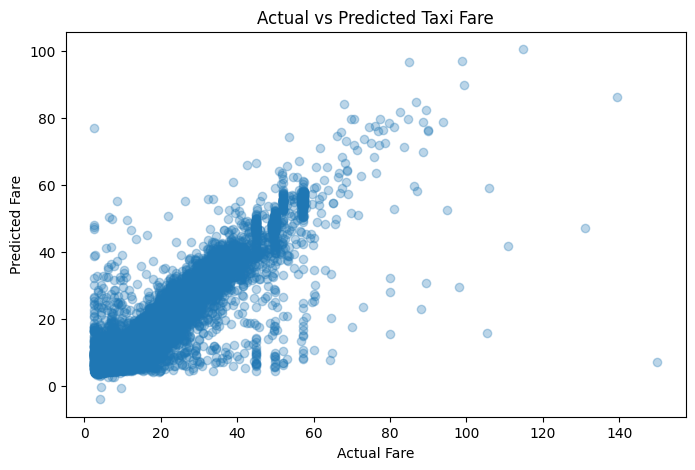

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Taxi Fare")

plt.show()

#Predict a new taxi fare

In [19]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Predicted Taxi Fare: ₹", round(prediction[0], 2))

Predicted Taxi Fare: ₹ 16.4


#